# Model 1: live classification

E3 classifies overlapping 30-second windows every 15 seconds. The live ride label is the category with the highest running mean of the window probabilities. The model has no recurrent memory: the mean carries the history. This notebook reads the trained model and existing evaluation artifacts; it does not train a model.

If artifacts are missing, start MLflow with `make dev-up` and run `uv run dvc repro evaluate`. Run from the repository root or `notebooks/`.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import mlflow
import pandas as pd
from ride_classifier.config import ID_COLUMN, LABEL_COLUMN, LABELS
from ride_classifier.viz.palette import CATEGORY_COLORS, MODEL_COLOR, REFERENCE_COLORS
from ride_classifier.viz.theme import apply_theme, save_fig

root = Path.cwd()
if not (root / "params.yaml").exists():
    root = root.parent
apply_theme()

C:\Users\Vincent\GitHub\Vincent-20-100\mlops-and-model-deployment-navy\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026/11/22 22:54:06 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at C:\Users\Vincent\GitHub\Vincent-20-100\mlops-and-model-deployment-navy\.venv\Lib\site-packages\mlflow\assistant\skills\instrumenting-with-mlflow-tracing\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


## Overlapping windows

The first answer is available after 30 seconds; each additional complete window updates the running average.

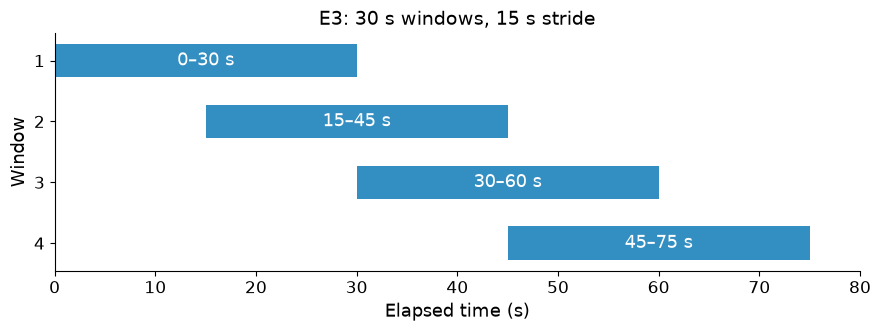

In [2]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for i, start in enumerate([0, 15, 30, 45]):
    ax.barh(i, 30, left=start, height=0.55, color=MODEL_COLOR, alpha=0.8)
    ax.text(start + 15, i, f"{start}–{start + 30} s", color="white", ha="center", va="center")
ax.set(xlabel="Elapsed time (s)", ylabel="Window", yticks=range(4), yticklabels=["1", "2", "3", "4"],
       title="E3: 30 s windows, 15 s stride", xlim=(0, 80))
ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, "F06", "ride_windows")
plt.show()

## One held-out ride

The first ride in sorted ID order is shown as an example, without selecting it for its result. Both curves use the category predicted at the end of that ride; the running mean at each point uses only completed windows. The known category is shown for context.

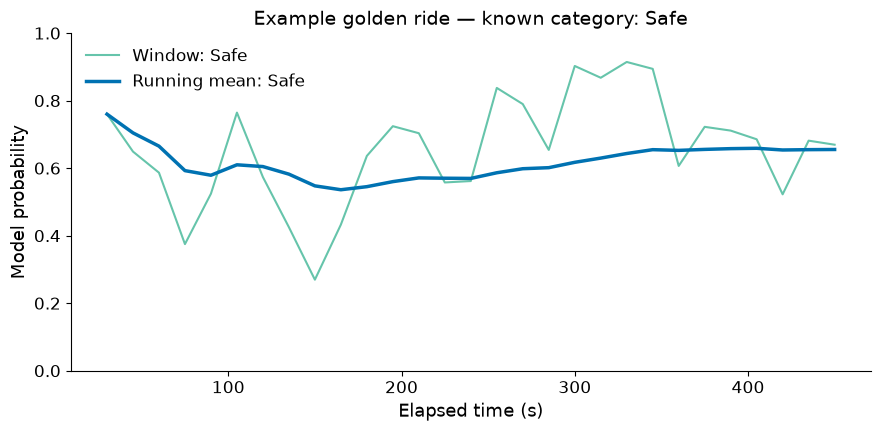

In [3]:
golden = pd.read_parquet(root / "data/processed/golden.parquet")
ride_id = sorted(golden[ID_COLUMN].unique())[0]
ride = golden[golden[ID_COLUMN] == ride_id]
known = ride[LABEL_COLUMN].iloc[0]
model = mlflow.pyfunc.load_model(str(root / "artifacts/model")).unwrap_python_model()
timeline = model.predict_timeline(ride.drop(columns=LABEL_COLUMN))
category = timeline.label
index = LABELS.index(category)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(timeline.end_s, timeline.window_probas[:, index], alpha=0.6, color=CATEGORY_COLORS[category],
        label=f"Window: {category}")
ax.plot(timeline.end_s, timeline.cumulative[:, index], linewidth=2.5, color=MODEL_COLOR,
        label=f"Running mean: {category}")
ax.set(xlabel="Elapsed time (s)", ylabel="Model probability", ylim=(0, 1),
       title=f"Example golden ride — known category: {known}")
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "F07", "window_vs_cumulative")
plt.show()

## Macro-F1 as rides unfold

After a ride ends its last prediction is retained. Thus the 300 s and 600 s points include completed rides; the table reports how many still have a window ending at or after each time. Horizontal references are whole-ride scores, not time-specific reference measurements.

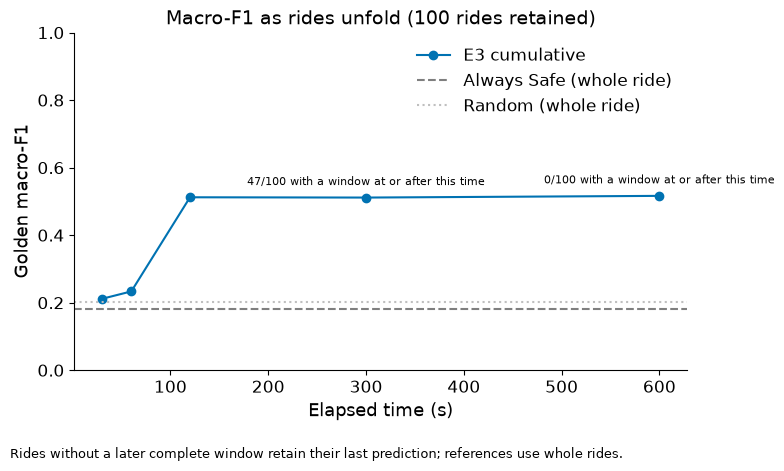

,t_s,t_label,macro_f1,n_rides,n_rides_complete
0,30.0,30,0.211499,100,100
1,60.0,60,0.233465,100,100
2,120.0,120,0.512242,100,100
3,300.0,300,0.511394,100,47
4,600.0,600,0.516411,100,0
5,inf,end,0.516411,100,100


In [4]:
elapsed = pd.read_csv(root / "artifacts/golden_f1_vs_elapsed.csv")
metrics = json.loads((root / "artifacts/golden_metrics.json").read_text(encoding="utf-8"))
finite = elapsed[elapsed["t_label"] != "end"]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(finite["t_s"], finite["macro_f1"], marker="o", color=MODEL_COLOR, label="E3 cumulative")
ax.axhline(metrics["golden_ref_majority_macro_f1"], color=REFERENCE_COLORS["majority"], linestyle="--",
           label="Always Safe (whole ride)")
ax.axhline(metrics["golden_ref_random_macro_f1"], color=REFERENCE_COLORS["random"], linestyle=":",
           label="Random (whole ride)")
for row in finite[finite["t_s"] >= 300].itertuples():
    ax.annotate(f"{row.n_rides_complete}/100 with a window at or after this time", (row.t_s, row.macro_f1),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8)
ax.set(xlabel="Elapsed time (s)", ylabel="Golden macro-F1", ylim=(0, 1),
       title="Macro-F1 as rides unfold (100 rides retained)")
fig.text(0.02, -0.04, "Rides without a later complete window retain their last prediction; references use whole rides.", fontsize=9)
ax.legend(frameon=False)
fig.tight_layout()
save_fig(fig, "F08", "golden_f1_vs_elapsed")
plt.show()
elapsed

## Window-length study behind model 2

These are development-group measurements of the earlier label-free score, with a 2-second margin. They motivated the 10-second window; they are not results from the final fall-risk model. The 5-second result may include the start of the fall. The final model uses a 5-second gap and a 10-second check.

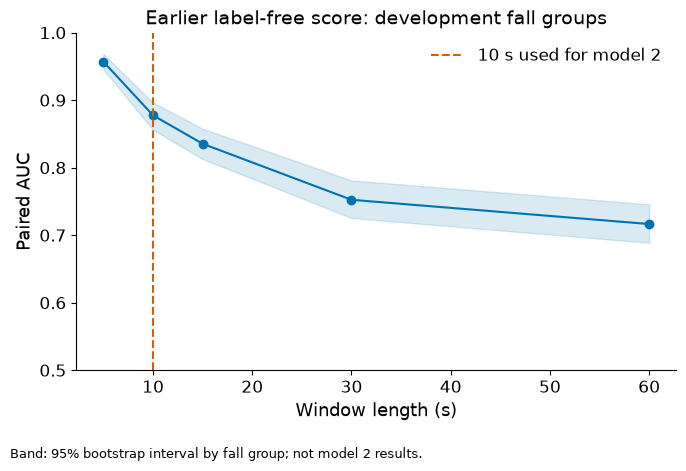

In [5]:
study = pd.read_csv(root / "artifacts/window_study.csv").sort_values("window_s")
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(study["window_s"], study["auc_fall"], marker="o", color=MODEL_COLOR)
ax.fill_between(study["window_s"], study["auc_fall_ci_low"], study["auc_fall_ci_high"], color=MODEL_COLOR, alpha=0.15)
ax.axvline(10, color="#D55E00", linestyle="--", label="10 s used for model 2")
ax.set(xlabel="Window length (s)", ylabel="Paired AUC", ylim=(0.5, 1), title="Earlier label-free score: development fall groups")
ax.legend(frameon=False)
fig.text(0.02, -0.04, "Band: 95% bootstrap interval by fall group; not model 2 results.", fontsize=9)
fig.tight_layout()
save_fig(fig, "F47", "window_length_study")
plt.show()

## Two aggregations, two questions

Model 1 uses the complete history of its window predictions. Model 2 scores the current 10-second window independently; its risk is not a cumulative ride label.

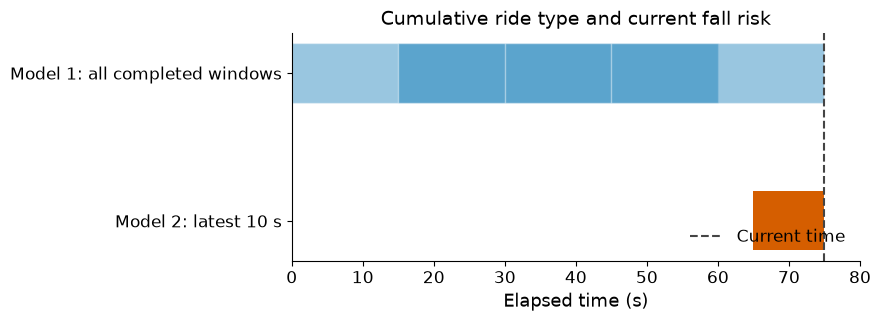

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for start in [0, 15, 30, 45]:
    ax.barh(1, 30, left=start, height=0.4, color=MODEL_COLOR, alpha=0.4, edgecolor="white")
ax.barh(0, 10, left=65, height=0.4, color="#D55E00")
ax.axvline(75, color="#444444", linestyle="--", label="Current time")
ax.set(xlim=(0, 80), yticks=[0, 1], yticklabels=["Model 2: latest 10 s", "Model 1: all completed windows"],
       xlabel="Elapsed time (s)", title="Cumulative ride type and current fall risk")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
save_fig(fig, "F48", "cumulative_vs_sliding")
plt.show()